# SE201 Week 3 · Gradient Descent

You will write two lines of code in this notebook. Everything else is given.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Colours, so the plots match the lecture slides. Change them if you like.
NAVY, GOLD, TEAL, GREY = '#1F3864', '#C8A227', '#2E8B85', '#9AA0A6'

---
## The optimisation problem
There are two optimisation problems below. The first is the one worked by hand in the
lecture. Change `PROBLEM` to switch between them and re-run from this cell.

The code you write should work to solve both problems.


In [2]:
PROBLEMS = {
    'lecture': dict(
        label  = 'L(w) = (w - 3)^2',
        L      = lambda w: (w - 3)**2,
        start  = 0.0,       # where the descent begins
        lr     = 0.2,       # learning rate
        steps  = 8,
        window = (-1.0, 7.0),   # plotting range
        probe  = 0.0,       # where we measure a slope in Part 1
        view_width = 0.4,   # how much of w the right-hand plot shows
        note   = 'The one worked by hand in class. One valley, minimum at w = 3.',
    ),
    'bumpy': dict(
        label  = 'L(w) = 2w^3 - 3w^2 + 7',
        L      = lambda w: 2*w**3 - 3*w**2 + 7,
        start  = 0.5,
        lr     = 0.01,
        steps  = 100,
        window = (-1.0, 3.0),
        probe  = 0.5,
        view_width = 0.5,
        note   = 'A harder shape. A dip on one side, falling away on the other.',
    ),
}

PROBLEM = 'lecture'          # <<<< change to 'bumpy' for the second example

cfg = PROBLEMS[PROBLEM]
L   = cfg['L']

print(f"problem : {PROBLEM}  ({cfg['label']})")
print(f"          {cfg['note']}")
print(f"start   : w = {cfg['start']},  learning rate = {cfg['lr']},  {cfg['steps']} steps")

problem : lecture  (L(w) = (w - 3)^2)
          The one worked by hand in class. One valley, minimum at w = 3.
start   : w = 0.0,  learning rate = 0.2,  8 steps


---
## Part 1 — Measure a slope

You do not need calculus for this. You need the method from the lecture.

Pick a position `w`. Move a tiny distance `h` away from it and ask the loss
function what it is worth there. The loss changed by some amount over a
distance you chose, and

```
slope  =  change in loss  /  distance moved
```

That is it. Two calls to `L` and one division, and it works on any function at
all — you never have to know what `L` is, only how to call it.

**Your job:** fill in `slope()` below.

- `L(w)` gives you the loss at `w`
- `h` is the small distance, already chosen for you as `1e-5`
- return the slope at `w`

The lecture used a one-sided step: measure at `w`, measure again at `w + h`,
and divide the difference by `h`. 

Measuring on *both* sides, from `w - h` to `w + h` with a distance of `2h`, is slightly more accurate, and
also works.

Either will pass the checks below.


In [ ]:
def slope(L, w, h=1e-5):
    """Measure the slope of L at the position w.

    Move a small distance h, see how much L changed, and divide by the
    distance moved.
    """
    # <<<< FILL THIS IN >>>>
    return (L(w+h) - L(w)) / h #slope = change in loss/ h = (L(w+h) - L(w)) / h

### Does it work?

On the left is the whole curve, with the point
you measured marked and the view boxed. On the right is that box blown
up, with a straight line drawn through the point using **the slope your function
returned**.

If your `slope()` is right, that line will lie along the curve (tangent). 

If it is wrong, the line will cut across it at the wrong angle. If you have not filled it
in yet, the line will be flat.


slope at w = 0.0 is -6.0000


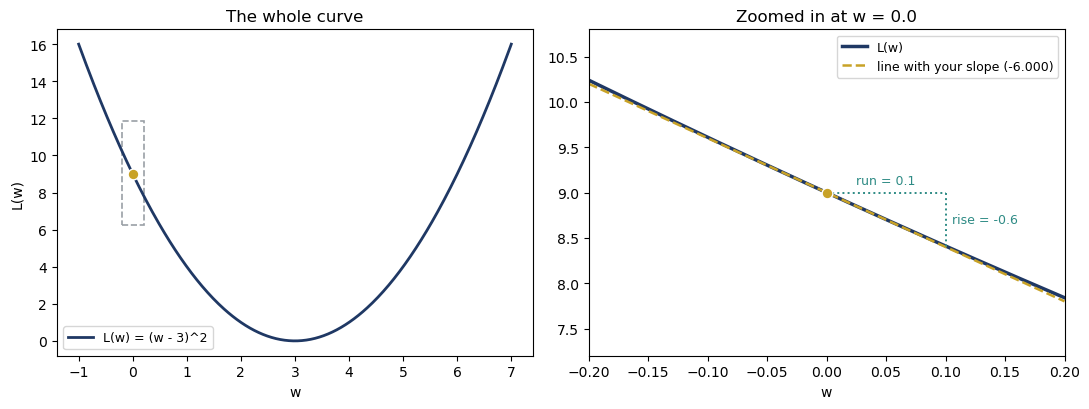

In [4]:
w0   = cfg['probe']
view_width = cfg['view_width']
s    = slope(L, w0)

print(f'slope at w = {w0} is {s:.4f}')
if abs(s) < 1e-12:
    print('  ... that is exactly zero. If the curve is not flat here, slope() is not filled in yet.')

lo, hi  = cfg['window']
ws      = np.linspace(lo, hi, 400)

#  Keep the view inside the plotted window. Without this, a view wider than
#  the window makes the dashed box below drag the left-hand axes out past the
#  ends of the curve, and the curve floats with blank space beside it.
half_w   = view_width / 2
zlo, zhi = max(lo, w0 - half_w), min(hi, w0 + half_w)
zws      = np.linspace(zlo, zhi, 200)
if (zlo, zhi) != (w0 - half_w, w0 + half_w):
    print(f'  view trimmed to the plotting window: {zlo:.4g} to {zhi:.4g}')
tangent = L(w0) + s * (zws - w0)          # a straight line through (w0, L(w0))

fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 4.2))

# --- left: the whole curve, with the view boxed
axL.plot(ws, L(ws), lw=2, color=NAVY, label=cfg['label'])
axL.scatter([w0], [L(w0)], s=60, color=GOLD, zorder=3, edgecolor='white')
zy  = L(zws)
pad = 0.10 * (L(ws).max() - L(ws).min())
axL.add_patch(plt.Rectangle((zlo, zy.min() - pad), zhi - zlo,
                            (zy.max() - zy.min()) + 2*pad,
                            fill=False, ls='--', lw=1.2, color=GREY))
axL.set_xlabel('w'); axL.set_ylabel('L(w)')
axL.set_title('The whole curve')
axL.legend(loc='best', fontsize=9)

# --- right: just the view, with your slope drawn as a line
axR.plot(zws, L(zws), lw=2.5, color=NAVY, label='L(w)')
axR.plot(zws, tangent, lw=1.8, ls='--', color=GOLD,
         label=f'line with your slope ({s:.3f})')

# rise over run, drawn over a distance you can actually see, and never past
# the right-hand edge of the view
d = min(0.25 * (zhi - zlo), zhi - w0)
axR.plot([w0, w0 + d], [L(w0), L(w0)], ls=':', lw=1.4, color=TEAL)
axR.plot([w0 + d, w0 + d], [L(w0), L(w0) + s*d], ls=':', lw=1.4, color=TEAL)
axR.annotate(f'run = {d:.3g}', (w0 + d/2, L(w0)), color=TEAL, fontsize=9,
             ha='center', va='bottom' if s < 0 else 'top',
             xytext=(0, 4 if s < 0 else -4), textcoords='offset points')
axR.annotate(f'rise = {s*d:.3g}', (w0 + d, L(w0) + s*d/2), color=TEAL, fontsize=9,
             ha='left', va='center', xytext=(5, 0), textcoords='offset points')

axR.scatter([w0], [L(w0)], s=60, color=GOLD, zorder=4, edgecolor='white')

#  Fix the shape of this panel: its height is always the same multiple of its
#  width, so your slope line leaves the axes at the same angle at every width.
#  The only thing that changes is how far the curve bends away from the line.
#  Letting the y axis rescale to fit instead would make the curve look equally
#  curved however narrow the view, which is the opposite of the point.
if abs(s) > 1e-12:
    half_h = 0.75 * abs(s) * (zhi - zlo)
    mid    = L(w0) + s * ((zlo + zhi) / 2 - w0)    # midpoint of your line
    axR.set_xlim(zlo, zhi)
    axR.set_ylim(mid - half_h, mid + half_h)
else:                                              # slope() not filled in yet
    ys = np.concatenate([L(zws), tangent, [L(w0), L(w0) + s*d]])
    m  = 0.12 * (ys.max() - ys.min() + 1e-12)
    axR.set_ylim(ys.min() - m, ys.max() + m)
axR.set_xlabel('w')
axR.set_title(f'Zoomed in at w = {w0}')
axR.legend(loc='best', fontsize=9)

plt.tight_layout(); plt.show()


**Question.** Look at a small enough piece of any smooth curve and it stops
looking curved.

Widen the view: set `view_width` in the problem to `10` and re-run. Then narrow
it right down to `0.1` and re-run again.

At which of the three does the straight line stop being a good description of
the curve, and why does that matter for a training step?

_Your answer:_


---
## Part 2 — Fill in the update equation

This is the gradient descent update rule from the lecture:

```
new weight  =  old weight  -  ( learning rate x slope )
```

**Your job:** write that one line inside `update()`. 

* `slope(L, w)` from Part 1 to give you the slope at the current position
* `lr` is the learning rate
* `w` is the current position



In [ ]:
def update(w, lr, L):
    """Take one step of gradient descent and return the new weight.

        new weight = old weight - (learning rate x slope)

    Use slope(L, w) to get the slope at the current position.
    """
    # <<<< FILL THIS IN >>>>
    return w - (lr * slope(L, w)) # new w = w - (learning rate * slope)

def descend(w, lr, steps, L):
    """Run the update repeatedly. Returns the path taken."""
    path = [w]
    for _ in range(steps):
        w = update(w, lr, L)     # the whole algorithm is this line
        path.append(w)
    return np.array(path)

path = descend(cfg['start'], cfg['lr'], cfg['steps'], L)

print('Finished at w =', round(float(path[-1]), 4))
print('Loss at w    =', round(float(L(path[-1])), 4))

steps_taken = np.abs(np.diff(path))
idx = np.unique(np.linspace(0, len(steps_taken) - 1, 5).astype(int))
# idx counts the gaps from 0, but the first gap is step 1, so print idx + 1.
print('size of steps', (idx + 1).tolist(), ':', np.round(steps_taken[idx], 5))

Finished at w = 2.9496
Loss at w    = 0.0025
size of steps [1, 2, 4, 6, 8] : [1.2     0.72    0.2592  0.09331 0.03359]


### Plot the descent steps

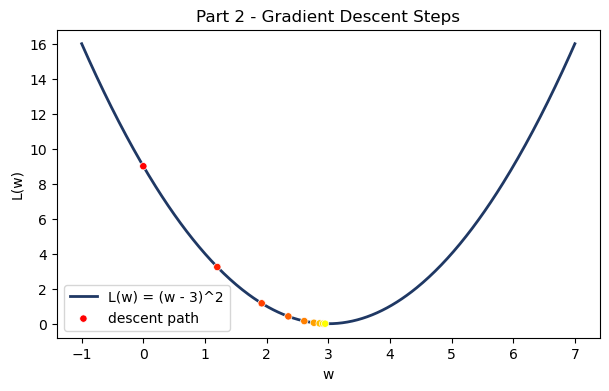

In [6]:
lo, hi = cfg['window']
ws = np.linspace(lo, hi, 400)

plt.figure(figsize=(7, 4))
plt.plot(ws, L(ws), lw=2, color=NAVY, label=cfg['label'])
plt.scatter(path, L(path), c=np.arange(len(path)), cmap='autumn', s=28,
            zorder=3, edgecolor='white', linewidth=0.5, label='descent path')
plt.xlabel('w'); plt.ylabel('L(w)')
plt.legend(); plt.title('Part 2 - Gradient Descent Steps')
plt.show()

### Check your solution

The lecture worked the first four steps of `L(w) = (w - 3)^2` by hand, starting
at `w = 0` with a learning rate of `0.2`. 

If both `slope()` and `update()` are right, you will reproduce those numbers.


In [ ]:
expected = [0.0, 1.2, 1.92, 2.352, 2.6112]
got = descend(0.0, 0.2, 4, lambda w: (w - 3)**2)

if np.allclose(got, expected, atol=1e-3):
    print('Correct. Your code reproduces the by-hand trace from the lecture:')
    print('   ', np.round(got, 4))
else:
    print('Not right yet.')
    print('  your code gives   :', np.round(got, 4))
    print('  the lecture worked:', expected)

**Question.** The step sizes shrink as it approaches the minimum.
Why does it happen?

_Your answer:_ As you get closer to the minimum, slope also decreases (less steep). Hence, step size shrinks (think of it like climbing a mountain, when its flat you can take smaller steps)


### Now try the other function

Go back to the setup cell, change

```python
PROBLEM = 'lecture'      ->      PROBLEM = 'bumpy'
```

and re-run from there. Neither `slope()` nor `update()` need to change.

**Question 1.** Where does it settle? Look at the curve you plotted. Is that the
lowest point on the plot?

**Question 2.** Now change `start` for the `bumpy` problem from `0.5` to `-0.5` and re-run. 

The weight runs off to a huge negative number instead of converging.

What is the descent doing, and what does the curve do to the
left of where you started?

_Your answer:_


---
## Part 3 — Three starts, three answers

A surface with several valleys:

$L(x, y) = (x^2-1)^2 + (y^2-1)^2 + \cos(2\pi x) + \cos(2\pi y)$

Run the descent from **three different starting points**. Note where each descent ends.


In [7]:
# L is already taken by the one-weight loss set up at the start, so the
# two-weight version is L_xy. It is the same idea: a loss, given the weights.
def L_xy(x, y):
    return (x**2-1)**2 + (y**2-1)**2 + np.cos(2*np.pi*x) + np.cos(2*np.pi*y)

def slope_xy(x, y, h=1e-5):
    """The same measurement as slope(), once for each of the two weights."""
    return np.array([(L_xy(x + h, y) - L_xy(x - h, y)) / (2*h),
                     (L_xy(x, y + h) - L_xy(x, y - h)) / (2*h)])

def descend_xy(start, lr=0.01, steps=300):
    """Run the descent, keeping every position so the path can be drawn."""
    p    = np.array(start, dtype=float)
    path = [p.copy()]
    for _ in range(steps):
        p = p - lr * slope_xy(*p)    # both weights updated at the same time
        path.append(p.copy())
    return np.array(path)

# The first two starts are close together on purpose.
STARTS = [(1.0, 1.0), (1.5, 1.5), (-3.2, 1.0)]
paths  = {start: descend_xy(start) for start in STARTS}

for start in STARTS:
    end = paths[start][-1]
    print(f'start {str(start):14s} -> ended ({end[0]:6.3f}, {end[1]:6.3f})',
          f'  loss {L_xy(*end):.4f}')

start (1.0, 1.0)     -> ended ( 0.539,  0.539)   loss -0.9335
start (1.5, 1.5)     -> ended ( 1.365,  1.365)   loss 0.1677
start (-3.2, 1.0)    -> ended (-1.365,  0.539)   loss -0.3829


### Plot the paths

The surface is drawn from above, as a contour map: the colour is the loss, and
the pale patches are the valleys. 

Each line is one run, with a square at the start and a dot at the end.

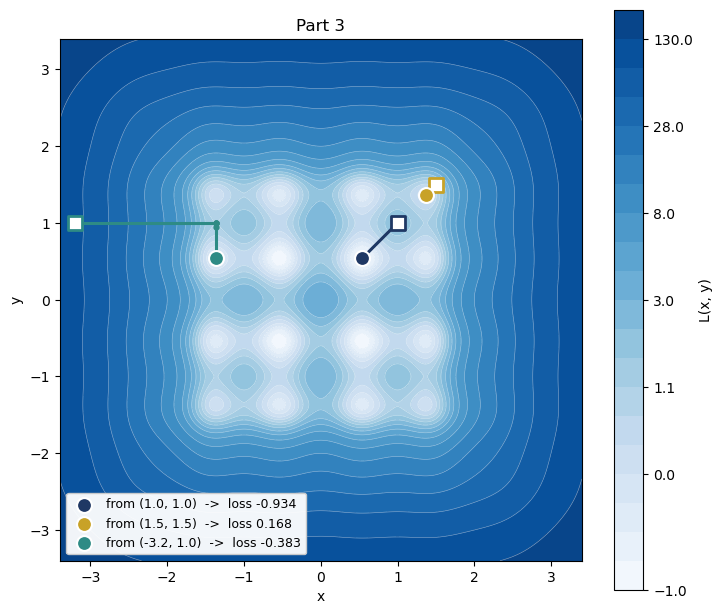

In [8]:
lo, hi = -3.4, 3.4
X, Y = np.meshgrid(np.linspace(lo, hi, 500), np.linspace(lo, hi, 500))
Z = L_xy(X, Y)

# The surface climbs to about 250 out at the corners, but the valleys differ
# from each other by less than one, so evenly spaced contours would hide
# everything worth seeing. These levels are deliberately uneven: fine near the
# bottom, coarse higher up.
levels = [-1, -0.75, -0.5, -0.25, 0, 0.35, 0.7, 1.1, 1.6, 2.2, 3,
          4, 5.5, 8, 12, 18, 28, 45, 75, 130, 260]
shades = plt.get_cmap('Blues')(np.linspace(0.03, 0.92, len(levels) - 1))

plt.figure(figsize=(7.4, 6.4))
plt.contourf(X, Y, Z, levels=levels, colors=shades)
cb = plt.colorbar(ticks=[-1, 0, 1.1, 3, 8, 28, 130])
cb.set_label('L(x, y)')
plt.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.4, alpha=0.55)

for start, colour in zip(STARTS, [NAVY, GOLD, TEAL]):
    p = paths[start]
    plt.plot(p[:, 0], p[:, 1], lw=2.2, color=colour, zorder=3)
    plt.plot(p[::20, 0], p[::20, 1], 'o', ms=3.5, color=colour, zorder=4)
    plt.scatter(*p[0], marker='s', s=95, facecolor='white', edgecolor=colour,
                linewidth=2, zorder=5)
    plt.scatter(*p[-1], marker='o', s=115, color=colour, edgecolor='white',
                linewidth=1.5, zorder=5,
                label=f'from {start}  ->  loss {L_xy(*p[-1]):.3f}')

plt.xlabel('x'); plt.ylabel('y')
plt.title('Part 3')
plt.legend(loc='lower left', fontsize=9, framealpha=0.95)
plt.gca().set_aspect('equal')
plt.tight_layout(); plt.show()

### Spin it

The same surface in 3D. **Drag to rotate it, scroll to zoom.**

Only the middle of the map is drawn: the sides climb to about 250, which would
flatten the plot. The coloured stalks mark where the three
runs ended.

Count the separate valleys, and notice there are ridges between them.
Gradient descent only measures the slope where it is currently standing, so it
has no way of knowing that a deeper valley sits just over the next ridge.

*Needs plotly (`pip install plotly`). Without it you get a fixed view instead.*

In [9]:
try:
    import plotly.graph_objects as go
    HAVE_PLOTLY = True
except ImportError:
    HAVE_PLOTLY = False
    print('plotly is not installed, so this is a fixed view you cannot rotate.')
    print('For the rotatable one:   pip install plotly')

VIEW   = 1.75      # draw only the middle; the sides climb to about 250
MARK_Z = 7.0       # all markers float at one height, so no ridge hides one

gx = np.linspace(-VIEW, VIEW, 260)
GX, GY = np.meshgrid(gx, gx)
GZ = L_xy(GX, GY)

if HAVE_PLOTLY:
    fig = go.Figure()
    fig.add_surface(x=gx, y=gx, z=GZ, colorscale='Blues', showscale=False,
                    opacity=0.93,
                    contours=dict(z=dict(show=True, color='white', width=1)))
    for start, colour in zip(STARTS, [NAVY, GOLD, TEAL]):
        ex, ey = paths[start][-1]
        ez = L_xy(ex, ey)
        fig.add_scatter3d(x=[ex, ex], y=[ey, ey], z=[ez, MARK_Z], mode='lines',
                          line=dict(color=colour, width=5), showlegend=False)
        fig.add_scatter3d(x=[ex], y=[ey], z=[MARK_Z], mode='markers',
                          marker=dict(size=10, color=colour,
                                      line=dict(color='white', width=1)),
                          name=f'from {start}  ->  loss {ez:.3f}')
    fig.update_layout(
        height=680, margin=dict(l=0, r=0, t=46, b=0),
        title='Part 3 - the valleys, and which one each run fell into',
        legend=dict(x=0.0, y=0.97),
        scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='L(x, y)',
                   aspectratio=dict(x=1, y=1, z=0.62),
                   camera=dict(eye=dict(x=1.35, y=-1.45, z=1.45))))
    fig.show()
else:
    ax = plt.figure(figsize=(8, 6.5)).add_subplot(projection='3d')
    ax.plot_surface(GX, GY, GZ, cmap='Blues', linewidth=0, antialiased=True,
                    alpha=0.95)
    for start, colour in zip(STARTS, [NAVY, GOLD, TEAL]):
        ex, ey = paths[start][-1]
        ez = L_xy(ex, ey)
        ax.plot([ex, ex], [ey, ey], [ez, MARK_Z], color=colour, lw=2)
        ax.scatter([ex], [ey], [MARK_Z], color=colour, s=60, edgecolor='white',
                   label=f'from {start}  ->  loss {ez:.3f}')
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('L(x, y)')
    ax.view_init(elev=38, azim=-52)
    ax.legend(loc='upper left', fontsize=8)
    plt.tight_layout(); plt.show()

Same code. Same function. **Three different answers.**

Look at the losses, not just the coordinates.

--> because each ends in their own local minimum (the white space), so by having random starts, you will end up with different models every time, which one is better or worse you can't really tell 

The first two starts differ by only 0.5 in each coordinate, and they end in
different valleys: one at -0.93, the other at 0.17. 

The third starts far away from both, and still beats the second one.

**Question.** What does this mean for different models trained with the same architecture and dataset?

_Your answer:_

---
## Part 4 — Break it

This code tries three learning rates on the problem you selected at the top.
One works, one is far too large, and one is far too small. 

Run it and look at the loss column.


In [ ]:
#learning rate (lr) is given by the data scientist, learned during training, not up to us to decide
def descend_safe(w, lr, steps, L):
    """Same descent, but bails out if it explodes."""
    for _ in range(steps):
        if not np.isfinite(w) or abs(w) > 1e8:
            return w, 'DIVERGED'
        w = update(w, lr, L)
    return w, 'ok'

for lr in [cfg['lr'], 1.5, 0.00001]:
    final, status = descend_safe(cfg['start'], lr, 50, L)
    val = L(final) if status == 'ok' else float('nan')
    print(f'lr={lr:<10} w={final:>14.4g}  L(w)={val:>12.4f}  {status}')

# When learning rate is too high, your line easily diverges 

lr=0.2        w=             3  L(w)=      0.0000  ok
lr=1.5        w=     1.006e+08  L(w)=         nan  DIVERGED
lr=1e-05      w=      0.002999  L(w)=      8.9820  ok


If it's too large, it overshoots the valley and the loss climbs, or even explodes to `inf`/`nan`.

If it's too small, it is correct but never arrives.

In a real training run, the wrong learning rate is millions of dollars of wasted compute. 